# Series de tiempo 3 — Modelos de suavización exponencial

## Objetivos de aprendizaje
1. Diferenciar una descomposición descriptiva de un modelo predictivo.
2. Comprender el suavizamiento exponencial simple (SES), Holt y Holt-Winters.
3. Interpretar nivel, tendencia, estacionalidad y parámetros de suavización.
4. Ajustar y comparar modelos con un conjunto de prueba temporal.
5. Reconocer las limitaciones de los datos financieros, festivos y valores faltantes.

**Bibliotecas:** `pandas`, `numpy`, `matplotlib`, `statsmodels`; `yfinance` es opcional para datos bursátiles.

## 1. De la descomposición al pronóstico

En el libro 2 utilizamos:

$$X_t=T_t+S_t+R_t$$

o, cuando las oscilaciones son proporcionales al nivel:

$$X_t=T_t S_t R_t.$$

Estas expresiones ayudan a **describir** una serie observada. La descomposición clásica no es, por sí sola, un modelo de pronóstico: no especifica necesariamente cómo evolucionarán los componentes después de la última fecha.

Los modelos de **suavización exponencial** actualizan estados como nivel, tendencia y estacionalidad conforme llegan observaciones. Luego extrapolan esos estados.

| Método | Nivel | Tendencia | Estacionalidad |
|---|---|---|---|
| Suavización exponencial simple (SES) | Sí | No | No |
| Holt | Sí | Sí | No |
| Holt con tendencia amortiguada | Sí | Sí, amortiguada | No |
| Holt-Winters aditivo | Sí | Opcional | Aditiva |
| Holt-Winters multiplicativo | Sí | Opcional | Multiplicativa |

**Importante:** un modelo que incluye tendencia no garantiza que exista una tendencia persistente en el proceso real. Siempre debemos comprobar sus pronósticos fuera de muestra.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
np.random.seed(42)

## 2. Un experimento controlado: una serie con tendencia y estacionalidad

Antes de utilizar datos reales, generaremos una serie **mensual** con período estacional conocido \(s=12\). Así podremos evaluar si el modelo recupera el patrón que nosotros mismos incorporamos.

Usaremos un ejemplo con nivel creciente, oscilaciones estacionales y ruido. No hay valores faltantes.

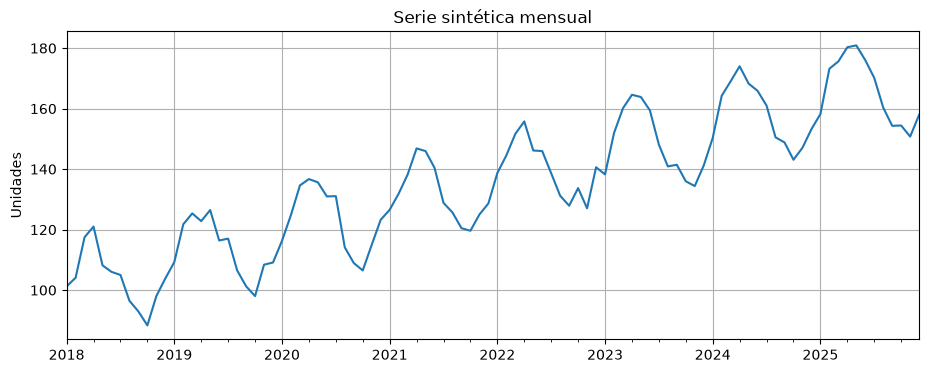

In [2]:
n = 96
fechas = pd.date_range("2018-01-01", periods=n, freq="MS")
t = np.arange(n)
rng = np.random.default_rng(42)
serie = pd.Series(
    100 + 0.75*t + 15*np.sin(2*np.pi*t/12) + rng.normal(0, 4, n),
    index=fechas, name="Demanda"
)
ax = serie.plot(title="Serie sintética mensual")
ax.set_ylabel("Unidades")
plt.show()

### 2.1 Revisar la descomposición

El período $12$ se conoce porque cada observación representa un mes y el patrón se repite anualmente. En la práctica, **el período estacional se justifica por el conocimiento del proceso y la exploración de los datos**, no solamente por la presencia de picos en un gráfico.

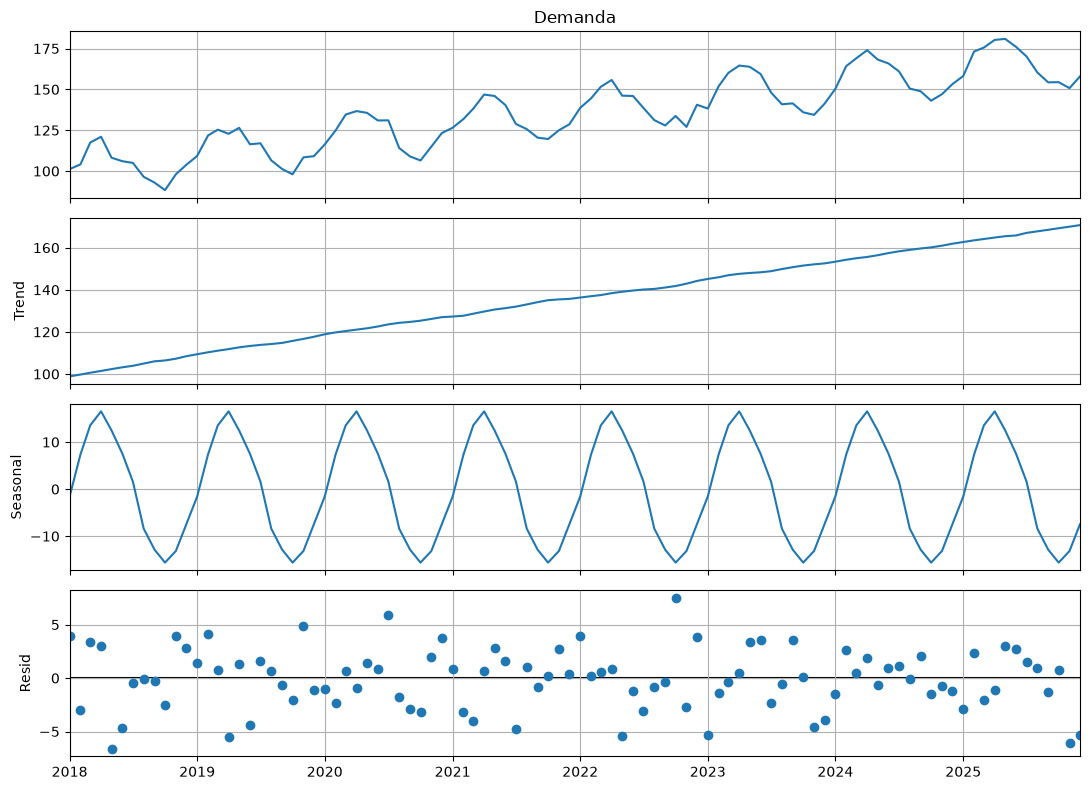

In [3]:
descomposicion = seasonal_decompose(
    serie, model="additive", period=12, extrapolate_trend="freq"
)
fig = descomposicion.plot()
fig.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

## 3. Separación temporal entre entrenamiento y prueba

Para evaluar un pronóstico debemos reservar las observaciones finales. No se deben mezclar aleatoriamente las fechas, ni utilizar información del conjunto de prueba al ajustar el modelo.

En este ejemplo entrenaremos con 72 meses y pronosticaremos los siguientes 24. **El horizonte de pronóstico** es la cantidad de períodos futuros.

In [4]:
train = serie.iloc[:72]
test = serie.iloc[72:]
h = len(test)

def graficar_pronostico(train, test, pred, titulo, ses=None, level=False):
    ax = train.plot(label="Entrenamiento", figsize=(11, 4))
    test.plot(ax=ax, label="Real (prueba)", color="black")
    pred.plot(ax=ax, label="Pronóstico", linestyle="--")
    if level:
        ses.level.plot(ax=ax, label="Nivel", linestyle="-")
    ax.set_title(titulo)
    ax.legend()
    plt.show()

def metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": np.mean(np.abs(y_real-y_pred)),
        "RMSE": np.sqrt(np.mean((y_real-y_pred)**2))
    }

print(f"Entrenamiento: {train.index.min().date()} a {train.index.max().date()}")
print(f"Prueba: {test.index.min().date()} a {test.index.max().date()}")

Entrenamiento: 2018-01-01 a 2023-12-01
Prueba: 2024-01-01 a 2025-12-01


## 4. Suavización exponencial simple (SES)

El modelo actualiza el nivel mediante:

$$\ell_t=\alpha X_t+(1-\alpha)\ell_{t-1},\qquad 0<\alpha\leq 1.$$

Su pronóstico para cualquier horizonte $h\geq 1$ es:

$$\widehat X_{t+h|t}=\ell_t.$$

La observación reciente recibe peso $\alpha$, y las anteriores reciben pesos geométricamente decrecientes. **SES no incorpora tendencia ni estacionalidad**: aquí lo ajustaremos deliberadamente como referencia para ver sus limitaciones.

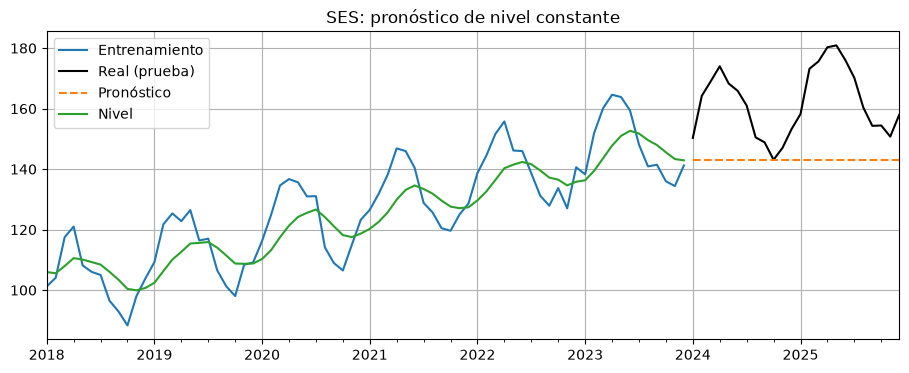

Parámetros: {'smoothing_level': np.float64(0.2), 'smoothing_trend': np.float64(nan), 'smoothing_seasonal': np.float64(nan), 'damping_trend': nan, 'initial_level': np.float64(107.14398544245022), 'initial_trend': np.float64(nan), 'initial_seasons': array([], dtype=float64), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}
Métricas: {'MAE': np.float64(19.081511642799505), 'RMSE': np.float64(22.01810786205991)}
Alfa estimado: 0.2


In [21]:
#El valor del smoothing indica qué tanto la estimación sigue a la curva original en sus cambios
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit(optimized=True,smoothing_level=0.2)
pred_ses = ses.forecast(h)
graficar_pronostico(train, test, pred_ses, "SES: pronóstico de nivel constante", ses, level=True)
print("Parámetros:", ses.params)
print("Métricas:", metricas(test, pred_ses))
print("Alfa estimado:", ses.params["smoothing_level"])

## 5. Modelo de Holt: nivel y tendencia

Holt incorpora una estimación de la pendiente:

$$\ell_t=\alpha X_t+(1-\alpha)(\ell_{t-1}+b_{t-1})$$

$$b_t=\beta^*(\ell_t-\ell_{t-1})+(1-\beta^*)b_{t-1}$$

$$\widehat X_{t+h|t}=\ell_t+h b_t.$$

Los parámetros $\alpha$ y $\beta^*$ controlan la adaptación del nivel y de la tendencia. Holt **no incorpora estacionalidad**, por lo que es esperable que no reproduzca las oscilaciones anuales de nuestro ejemplo.

C:\Users\000010478\AppData\Local\Temp\ipykernel_10012\2825955952.py:1: FutureWarning: the 'smoothing_slope' keyword is deprecated, use 'smoothing_trend' instead.
  holt = Holt(train, initialization_method="estimated").fit(optimized=True, smoothing_level=0.2, smoothing_slope=0.01)


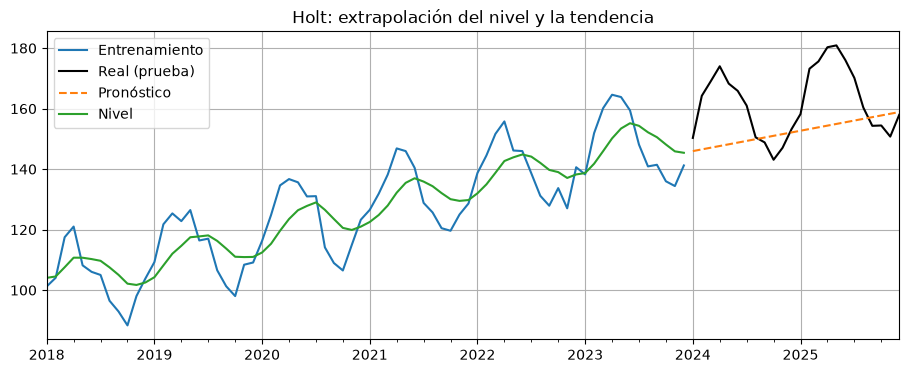

Parámetros: {'smoothing_level': np.float64(0.2), 'smoothing_trend': np.float64(0.01), 'smoothing_seasonal': np.float64(nan), 'damping_trend': nan, 'initial_level': np.float64(104.1869761725436), 'initial_trend': np.float64(0.573432691016276), 'initial_seasons': array([], dtype=float64), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}
Métricas: {'MAE': np.float64(11.964930630465643), 'RMSE': np.float64(14.986092341469385)}


In [28]:
holt = Holt(train, initialization_method="estimated").fit(optimized=True, smoothing_level=0.2, smoothing_slope=0.01)
pred_holt = holt.forecast(h)
graficar_pronostico(train, test, pred_holt, "Holt: extrapolación del nivel y la tendencia", holt, level=True)
print("Parámetros:", holt.params)
print("Métricas:", metricas(test, pred_holt))

## 6. Holt con tendencia amortiguada

La extrapolación lineal de Holt puede resultar excesiva en horizontes largos. Una alternativa introduce un factor $0<\phi<1$:

$$\widehat X_{t+h|t}=\ell_t+
\left(\sum_{j=1}^{h}\phi^j\right)b_t.$$

La contribución de la pendiente disminuye progresivamente. Esto **no garantiza** mejores pronósticos, pero permite contrastar una tendencia lineal indefinida frente a una tendencia amortiguada.

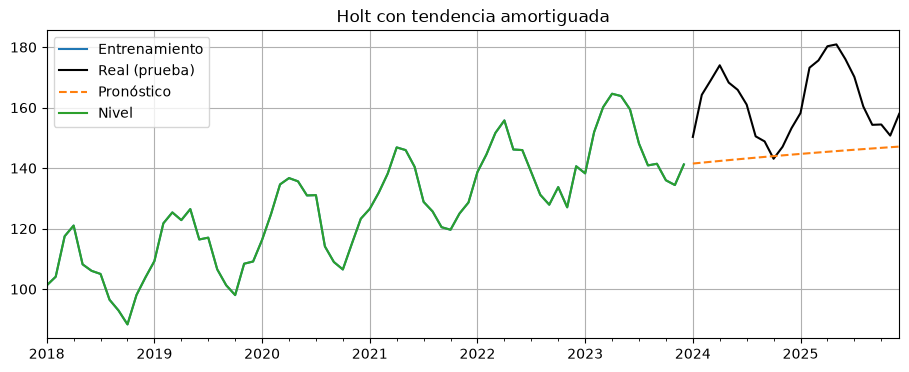

Factor de amortiguación: 0.9833209713662066
Métricas: {'MAE': np.float64(17.575720505230695), 'RMSE': np.float64(20.699152197865743)}


In [8]:
holt_amort = Holt(
    train, damped_trend=True, initialization_method="estimated"
).fit(optimized=True)
pred_holt_amort = holt_amort.forecast(h)
graficar_pronostico(train, test, pred_holt_amort, "Holt con tendencia amortiguada", holt_amort, level=True)
print("Factor de amortiguación:", holt_amort.params.get("damping_trend"))
print("Métricas:", metricas(test, pred_holt_amort))

## 7. Holt-Winters: tendencia y estacionalidad

En la variante aditiva, las ecuaciones de actualización son:

$$\ell_t=\alpha(X_t-s_{t-m})+(1-\alpha)(\ell_{t-1}+b_{t-1})$$

$$b_t=\beta^*(\ell_t-\ell_{t-1})+(1-\beta^*)b_{t-1}$$

$$s_t=\gamma(X_t-\ell_t)+(1-\gamma)s_{t-m}$$

y el pronóstico es:

$$\widehat X_{t+h|t}=\ell_t+h b_t+s_{t-m+1+((h-1)\bmod m)}.$$

Aquí $m=12$ y el componente estacional se expresa en **unidades aditivas**. En el caso multiplicativo, el efecto estacional escala con el nivel, por lo que requiere observaciones estrictamente positivas.

C:\Users\000010478\AppData\Local\Temp\ipykernel_10012\637536831.py:4: FutureWarning: the 'smoothing_slope' keyword is deprecated, use 'smoothing_trend' instead.
  ).fit(optimized=True, smoothing_level=0.2, smoothing_slope=0.1, smoothing_seasonal=0.1)


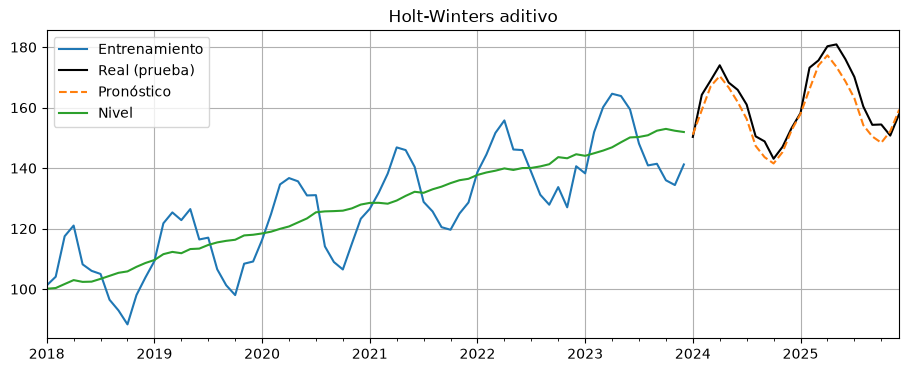

Parámetros: {'smoothing_level': np.float64(0.2), 'smoothing_trend': np.float64(0.1), 'smoothing_seasonal': np.float64(0.1), 'damping_trend': nan, 'initial_level': np.float64(98.76158165118338), 'initial_trend': np.float64(0.8044427414740456), 'initial_seasons': array([ -1.11555548,   6.2322798 ,  13.69595749,  16.25319824,
        11.7186973 ,   6.2449893 ,   0.64811155,  -9.04684563,
       -13.54478729, -16.35224136, -12.43641158,  -6.64555548]), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}
Métricas: {'MAE': np.float64(3.6166028452472823), 'RMSE': np.float64(4.286170951391785)}


In [29]:
hw_aditivo = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True, smoothing_level=0.2, smoothing_slope=0.1, smoothing_seasonal=0.1)
pred_hw_aditivo = hw_aditivo.forecast(h)
graficar_pronostico(train, test, pred_hw_aditivo, "Holt-Winters aditivo", hw_aditivo, level=True)
print("Parámetros:", hw_aditivo.params)
print("Métricas:", metricas(test, pred_hw_aditivo))

### 7.1 Variante multiplicativa

Cuando la amplitud de la oscilación estacional aumenta proporcionalmente al nivel, podemos probar estacionalidad multiplicativa.

**No debe escogerse solo porque un ajuste descriptivo multiplicativo se vea mejor:** lo importante es comparar pronósticos fuera de muestra y verificar que el modelo tenga sentido para la variable.

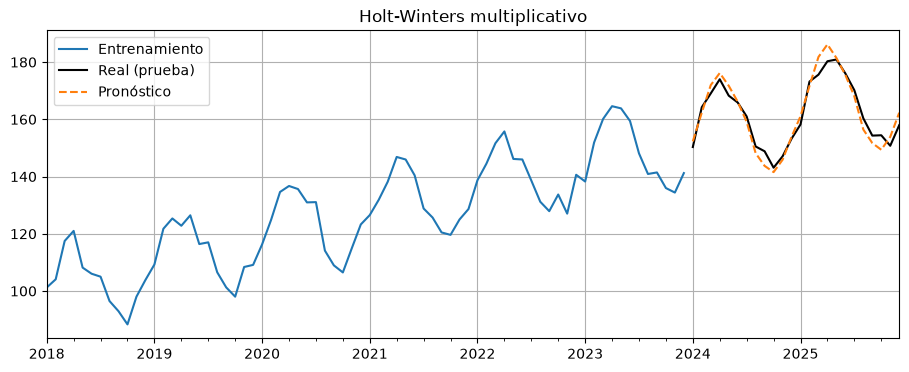

Métricas: {'MAE': np.float64(2.6740594082311566), 'RMSE': np.float64(3.1441921384469667)}


In [10]:
hw_multiplicativo = ExponentialSmoothing(
    train, trend="add", seasonal="mul", seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)
pred_hw_multiplicativo = hw_multiplicativo.forecast(h)
graficar_pronostico(train, test, pred_hw_multiplicativo, "Holt-Winters multiplicativo")
print("Métricas:", metricas(test, pred_hw_multiplicativo))

## 8. Comparar todos los métodos con el mismo horizonte

Agregaremos dos referencias sencillas:
- **Último valor:** todos los pronósticos son iguales a la última observación del entrenamiento.
- **Estacional ingenuo:** cada mes repite el valor del mismo mes del año anterior.

Estos referentes son esenciales: un modelo más elaborado solo es útil si aporta valor frente a pronósticos simples.

In [11]:
pred_ultimo = pd.Series(train.iloc[-1], index=test.index)
pred_estacional = pd.Series(
    np.resize(train.iloc[-12:].to_numpy(), len(test)),
    index=test.index
)
pronosticos = {
    "Último valor": pred_ultimo,
    "Estacional ingenuo": pred_estacional,
    "SES": pred_ses,
    "Holt": pred_holt,
    "Holt amortiguado": pred_holt_amort,
    "Holt-Winters aditivo": pred_hw_aditivo,
    "Holt-Winters multiplicativo": pred_hw_multiplicativo
}
comparacion = pd.DataFrame({
    nombre: metricas(test, pred) for nombre, pred in pronosticos.items()
}).T.sort_values("RMSE")
display(comparacion.round(2))

,MAE,RMSE
Holt-Winters multiplicativo,2.67,3.14
Holt-Winters aditivo,3.62,4.29
Estacional ingenuo,13.64,14.46
Holt,16.90,20.01
Holt amortiguado,17.58,20.70
SES,19.08,22.02
Último valor,20.77,23.50


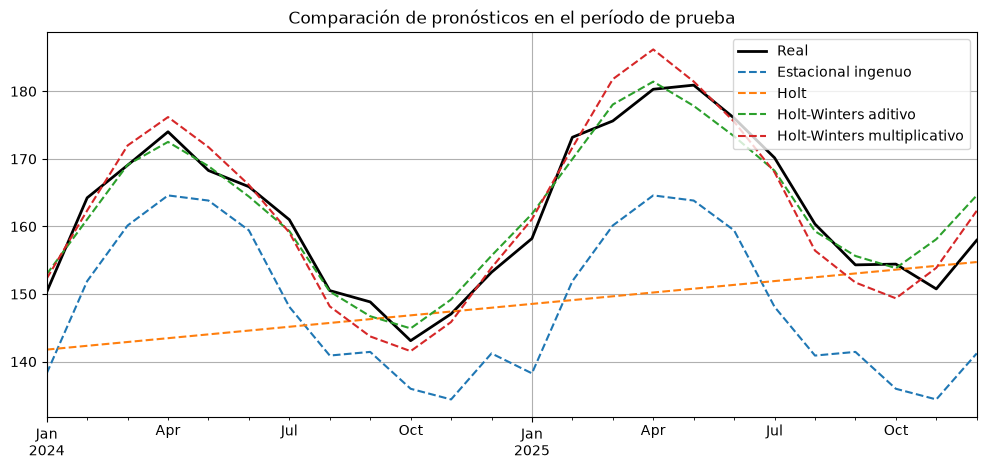

In [ ]:
ax = test.plot(color="black", linewidth=2, label="Real", figsize=(12, 5))
for nombre in ["Estacional ingenuo", "Holt", "Holt-Winters aditivo",
               "Holt-Winters multiplicativo"]:
    pronosticos[nombre].plot(ax=ax, linestyle="--", label=nombre)
ax.set_title("Comparación de pronósticos en el período de prueba")
ax.legend()
plt.show()

## 9. ¿Qué aprendemos de los parámetros y de los residuos?

Los modelos se ajustan buscando parámetros que reduzcan el error dentro del entrenamiento. Pero **el mejor ajuste de entrenamiento no equivale al mejor pronóstico**.

Inspeccionaremos los residuos de Holt-Winters y su autocorrelación. Si presentan dependencia significativa, el modelo puede estar dejando estructura temporal sin explicar.

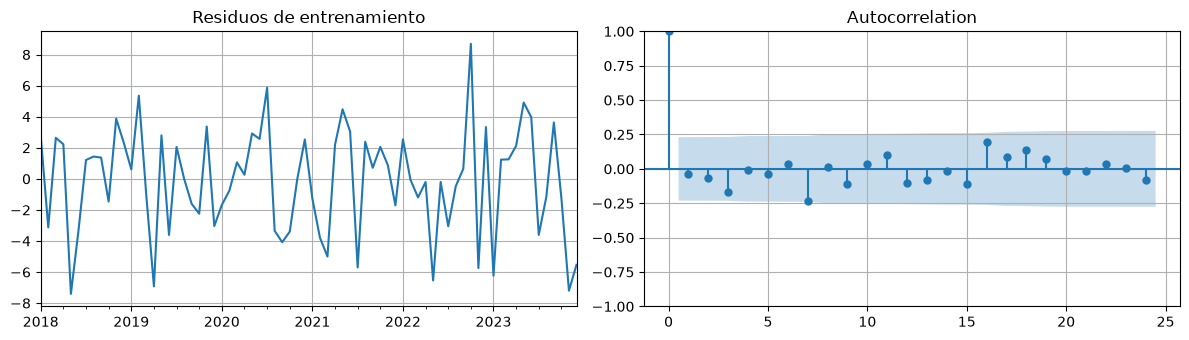

In [12]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

residuos = pd.Series(hw_aditivo.resid, index=train.index).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
residuos.plot(ax=ax[0], title="Residuos de entrenamiento")
plot_acf(residuos, lags=24, ax=ax[1])
plt.tight_layout()
plt.show()


## 10. Segundo experimento: datos de COVID-19 en Colombia 

El cuaderno 2 construía una serie de **casos nuevos diarios** a partir de casos acumulados. Aquí reproducimos esa transformación, pero sin reemplazar el primer valor indefinido por cero.

**Advertencia:** el archivo histórico puede contener revisiones, valores negativos por correcciones y patrones de notificación. La estacionalidad semanal podría reflejar el calendario de reporte, no necesariamente la dinámica epidemiológica.

Se recomienda ejecutar este ejercicio con acceso a Internet. Si el recurso histórico ya no está disponible, el experimento sintético anterior sigue siendo completamente ejecutable.

Datos diarios: 799


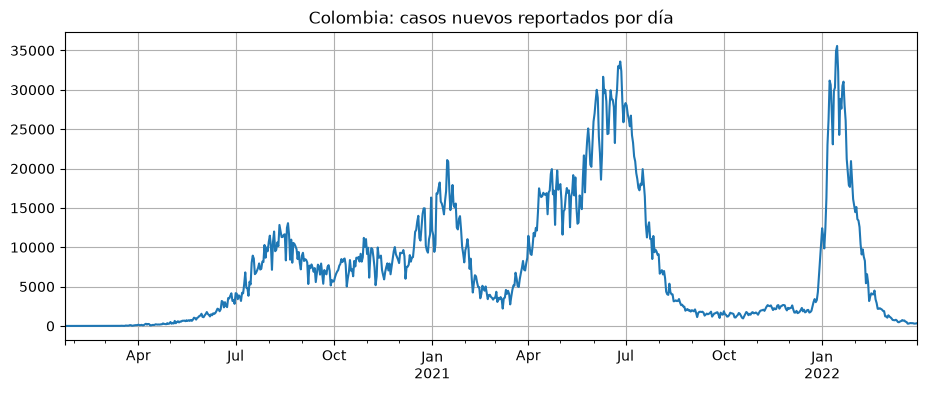

In [13]:
url_covid = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/"
    "master/csse_covid_19_data/csse_covid_19_time_series/"
    "time_series_covid19_confirmed_global.csv"
)
try:
    covid_raw = pd.read_csv(url_covid)
    covid_col = covid_raw.loc[covid_raw["Country/Region"] == "Colombia"]
    columnas_fechas = covid_raw.columns[4:]
    acumulados = covid_col[columnas_fechas].sum(axis=0)
    acumulados.index = pd.to_datetime(acumulados.index, format="%m/%d/%y")
    casos_diarios = acumulados.sort_index().diff().dropna().astype(float)
    casos_diarios = casos_diarios.loc[:"2022-03-31"].asfreq("D")
    print("Datos diarios:", casos_diarios.shape[0])
    casos_diarios.plot(title="Colombia: casos nuevos reportados por día")
    plt.show()
except Exception as exc:
    casos_diarios = None
    print("No fue posible descargar el archivo histórico:", exc)

### 10.1 Pronóstico semanal con Holt-Winters

Para un período de reporte semanal se puede considerar \(m=7\). Utilizaremos los últimos 28 días como prueba, **siempre que la serie esté disponible y no contenga faltantes**. En este ejemplo aplicamos el modelo aditivo, porque las series de conteos pueden incluir ceros.

El modelo no tiene conocimiento de intervenciones sanitarias, cambios en las pruebas ni otras causas externas; es un ejercicio de métodos, no un pronóstico epidemiológico validado.

C:\Users\000010478\AppData\Local\Temp\ipykernel_10012\2863257925.py:8: FutureWarning: the 'smoothing_slope' keyword is deprecated, use 'smoothing_trend' instead.
  ).fit(optimized=True, smoothing_level=0.1, smoothing_slope=0.3, smoothing_seasonal=0.1)


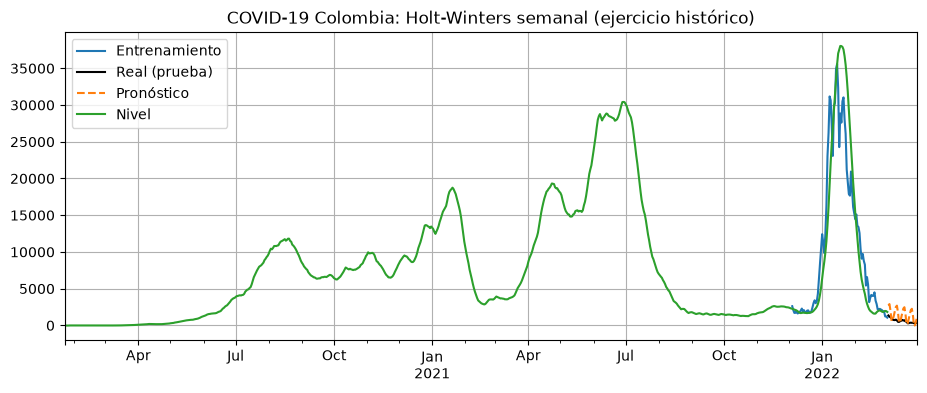

{'MAE': np.float64(916.0635383769142), 'RMSE': np.float64(1106.8330166492417)}


In [14]:
if casos_diarios is not None:
    datos = casos_diarios.dropna()
    if len(datos) >= 60:
        entrenamiento, prueba = datos.iloc[:-28], datos.iloc[-28:]
        modelo_covid = ExponentialSmoothing(
            entrenamiento, trend="add", seasonal="add",
            seasonal_periods=7, initialization_method="estimated"
        ).fit(optimized=True, smoothing_level=0.1, smoothing_slope=0.3, smoothing_seasonal=0.1)
        pronostico_covid = modelo_covid.forecast(len(prueba))
        graficar_pronostico(
            entrenamiento.iloc[-90:], prueba, pronostico_covid,
            "COVID-19 Colombia: Holt-Winters semanal (ejercicio histórico)", modelo_covid, level=True
        )
        print(metricas(prueba, pronostico_covid))
    else:
        print("No hay suficientes datos para este experimento.")
else:
    print("Ejercicio opcional omitido: sin datos descargados.")

## 11. Tercer experimento: Bitcoin

Bitcoin tiene observaciones diarias, incluidos fines de semana. Podemos conservar una frecuencia diaria y estudiar si un método con tendencia supera a la referencia del último valor.

**No supondremos automáticamente estacionalidad semanal:** que existan siete días por semana no implica que haya un patrón semanal estable en los precios.

Observaciones faltantes: 0


C:\Users\000010478\AppData\Local\Temp\ipykernel_10012\3333080836.py:17: FutureWarning: the 'smoothing_slope' keyword is deprecated, use 'smoothing_trend' instead.
  ).fit(optimized=True, smoothing_level=0.1, smoothing_slope=0.5, smoothing_seasonal=0.1)


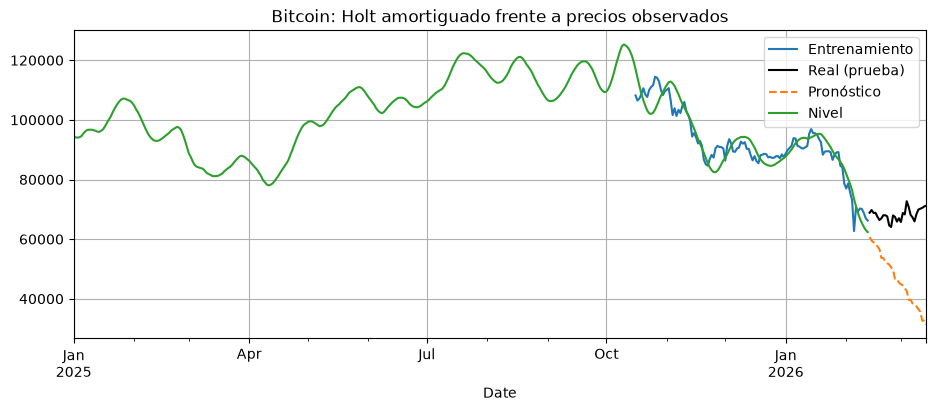

,MAE,RMSE
Holt amortiguado,21846.332766,23884.721479
Último valor,2324.323438,2801.160206


In [15]:
# Este experimento es opcional y necesita conexión a Internet.
try:
    import yfinance as yf
    btc = yf.Ticker("BTC-USD").history(
        start="2025-01-01", end="2026-03-15"
    )["Close"]
    btc.index = pd.to_datetime(btc.index).tz_localize(None).normalize()
    btc = btc.sort_index().asfreq("D")
    print("Observaciones faltantes:", btc.isna().sum())
    if btc.isna().any():
        print("No se interpolan automáticamente los precios faltantes.")
    else:
        btc_train, btc_test = btc.iloc[:-30], btc.iloc[-30:]
        btc_holt = ExponentialSmoothing(
            btc_train, trend="add", seasonal="add",
            seasonal_periods=7, initialization_method="estimated"
        ).fit(optimized=True, smoothing_level=0.1, smoothing_slope=0.5, smoothing_seasonal=0.1)
        btc_pred = btc_holt.forecast(len(btc_test))
        graficar_pronostico(
            btc_train.iloc[-120:], btc_test, btc_pred,
            "Bitcoin: Holt amortiguado frente a precios observados", btc_holt, level=True
        )
        btc_naive = pd.Series(btc_train.iloc[-1], index=btc_test.index)
        display(pd.DataFrame({
            "Holt amortiguado": metricas(btc_test, btc_pred),
            "Último valor": metricas(btc_test, btc_naive)
        }).T)
except Exception as exc:
    print("No se pudo ejecutar el ejemplo opcional de Bitcoin:", exc)

In [16]:
# Base de datos de salida de colombianos hacia el exterior, mensual y por pais
import pandas as pd
from sodapy import Socrata

client = Socrata("www.datos.gov.co", None)
results = client.get("efw5-jiej", limit=94000)

results_df = pd.DataFrame.from_records(results)
df=results_df.copy()
df['mes']=df['mes'].map({'Enero': 1, 'Febrero': 2, 'Marzo': 3, 'Abril': 4, 'Mayo': 5, 'Junio': 6, 'Julio': 7, 'Agosto': 8, 'Septiembre': 9, 'Octubre': 10, 'Noviembre': 11, 'Diciembre': 12})
df['dia']=1
df['fecha'] = pd.to_datetime(
    df.rename(columns={'a_o': 'year', 'mes': 'month', 'dia': 'day'})[
        ['year', 'month', 'day']
    ]
)
df.set_index('fecha', inplace=True)
df=df[['pa_s_destino','femenino','masculino','total']]
df['total']=pd.to_numeric(df['total'], errors='coerce')
df['pa_s_destino']=df['pa_s_destino'].str.upper()
df2=pd.pivot_table(df, index=df.index, columns='pa_s_destino', values='total', aggfunc='sum').fillna(0)
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["axes.grid"] = True



Observaciones faltantes: pa_s_destino
ESTADOS UNIDOS DE AMÉRICA    0
dtype: int64


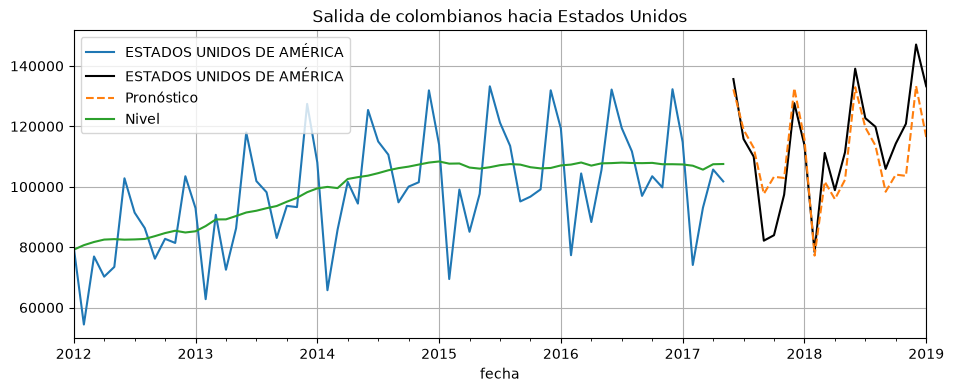

In [17]:
# Este experimento es opcional y necesita conexión a Internet.
y=df2[[ 'ESTADOS UNIDOS DE AMÉRICA']].loc[:"2019-01-01"]
y.index = pd.to_datetime(y.index).tz_localize(None).normalize()
y = y.sort_index().asfreq("MS")
print("Observaciones faltantes:", y.isna().sum())
y_train, y_test = y.iloc[:-20], y.iloc[-20:]
y_holt = ExponentialSmoothing(
            y_train, trend="add", seasonal="add",
            seasonal_periods=12, initialization_method="estimated"
        ).fit(optimized=True)
y_pred = y_holt.forecast(len(y_test))
graficar_pronostico(
    y_train, y_test, y_pred,
    "Salida de colombianos hacia Estados Unidos", y_holt, level=True
)
